# Parks and Transportation
For my part of the project, I decided to think about what made a neighborhood "good". In an urban environment like Pittsburgh, two things came to mind; the first being great public parks, the second being a good transit system. 

Recently, there was an effort by city officials to decide which parks needed better investing. They took into account a variety of factors to rank each park on it's investment priority. Using this file, I took the csv data and used as a metric to help decide which parks were considered the "best". While it isn't a perfect metric, it helps gives insight into the state of each park in the city. 

## Points
A park gets 1 point for each of these rankings:
- In good or excellent condition
- It needs less repairs
- Bigger than 10 acres
- Land within walking distance
- Rec facility in park limits
- Good tree cover
- Clean air
- Serves a high need neighborhood

# Higher number = "better" park

park_name
Banksville Park                            6.000000
Brookline Memorial Park                    6.000000
Brighton Heights Park                      6.000000
Riverview Park                             5.200000
Wightman Park                              5.000000
Phillips Park                              5.000000
Roland Lockridge Community Park            5.000000
Fowler Park                                5.000000
Warrington Park                            5.000000
Sheraden Senior Center                     5.000000
Homewood Senior Center                     5.000000
Paulson Park                               5.000000
Sheraden Park                              5.000000
East Hills Park                            5.000000
Highland Park                              4.571429
Schenley Park                              4.142857
Frick Park                                 4.125000
Southside Market House                     4.000000
Buhl Community Park at Allegheny Square    4.000000
Ma

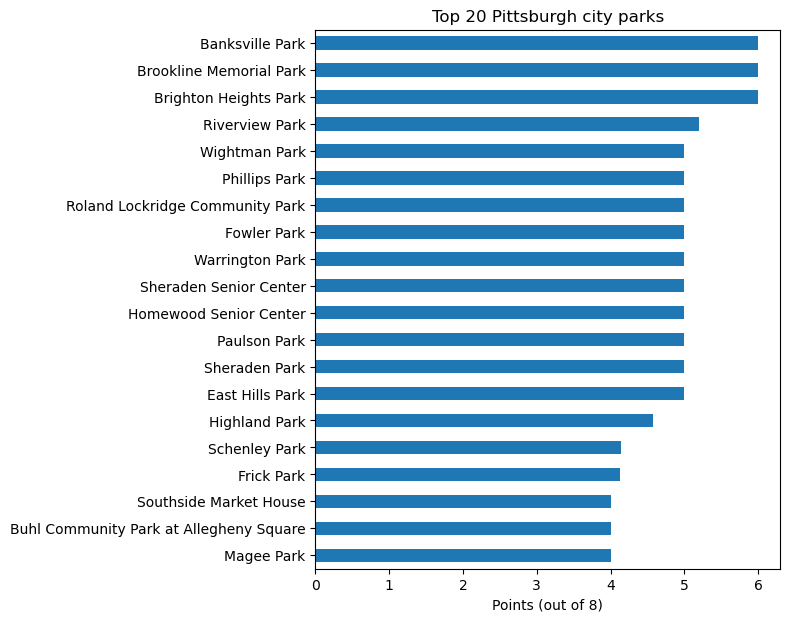

In [65]:
import pandas as pd

parks = pd.read_csv("/ihome/cmpinf0010-sec1300_2026f/lrl80/ParksAndTransit/pittsburgh_park_rankings.csv")

# Greenways have no scores, so drop them
parks = parks.dropna(subset=["site_condition_score"])
parks.head()

parks["points"] = (
    (parks["site_condition_score"] <= 33).astype(int)
    + (parks["investment_need_score"] < 90).astype(int)
    + (parks["site_acres"] > 10).astype(int)
    + (parks["walkshed_acres"] > 150).astype(int)
    + (parks["rec_facility"] == "Y").astype(int)
    + (parks["tree_canopy_score"] < 60).astype(int)
    + (parks["black_carbon_score"] < 60).astype(int)
    + (parks["community_need_score"] > 200).astype(int)
)

scores = parks.groupby("park_name")[["points", "investment_priority_score"]].mean()

# Sort by points. Ties are decided by need score
scores = scores.sort_values(["points", "investment_priority_score"], ascending=[False, True])

best = scores["points"].head(20)

# [::-1] flips the order so #1 is at the top of the chart
best[::-1].plot.barh(title="Top 20 Pittsburgh city parks", xlabel="Points (out of 8)", ylabel="", figsize=(6, 7))
best

# PRT Stops by Area 
Uses a csv I found detailing every stop that PRT services. An "area" is a Pittsburgh neighborhood/suburb.

In [66]:
import pandas as pd

stops = pd.read_csv("ParksAndTransit/prt_stops_with_amenities.csv")
stops.head()

,stop_id,stop_code,stop_name,stop_lat,stop_lon,routes_served,mode,direction,trips_weekday,trips_saturday,...,shelter_owner,shelter_type,shelter_lat,shelter_lon,has_ada_platform,has_real_time_screen,has_fare_machine,has_bike_rack,station_platform,amenity_count
0,E00175,2593,26TH ST AT PENN AVE FS (SPRING WAY),40.454586,-79.978073,"54,88,91",BUS,IB,120,81,...,NaN,NaN,NaN,NaN,False,False,False,False,NaN,0
1,E00180,2161,28TH ST AT LIBERTY AVE,40.456319,-79.974662,54,BUS,IB,28,18,...,NaN,NaN,NaN,NaN,False,False,False,False,NaN,0
2,E00270,2410,32ND ST AT SPRING WAY,40.460445,-79.969566,"54,88,91",BUS,OB,119,81,...,NaN,NaN,NaN,NaN,False,False,False,False,NaN,0
3,E00420,1199,40TH ST AT BUTLER ST,40.468544,-79.962105,93,BUS,OB,30,12,...,NaN,NaN,NaN,NaN,False,False,False,False,NaN,0
4,E00430,20106,40TH ST AT DAVIDSON ST FS,40.467739,-79.960861,93,BUS,OB,30,12,...,NaN,NaN,NaN,NaN,False,False,False,False,NaN,0


# The Best Stops
## Each stop gets 1 point for having each of these
- A shelter
- Arrival screen
- ADA platform
- Fare machine
- Bike Rack
- More than 300 buses/trains per week

An area's score is the average of all it's stops combined. Areas with less than 10 stops are left off

munihood_display
Castle Shannon bgh           3.600000
Bethel Park municipality     2.152174
South Shore                  2.133333
Central Business District    1.859155
Overbrook                    1.733333
Beechview                    1.555556
Allegheny Center             1.461538
Dormont bgh                  1.368421
Point Breeze North           1.235294
Sharpsburg bgh               1.228571
Name: points, dtype: float64

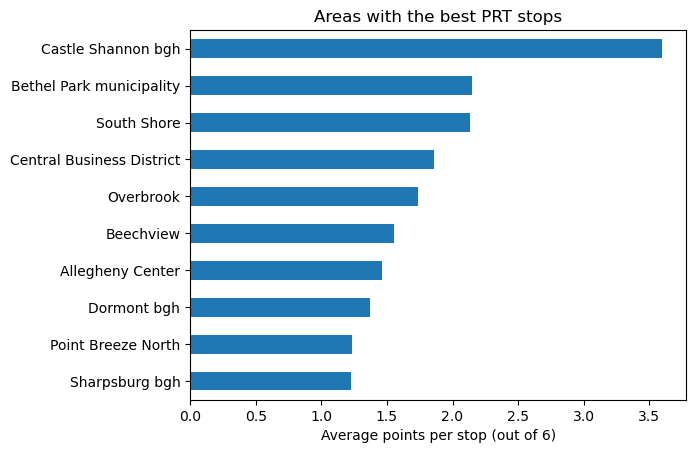

In [67]:
stops["points"] = (
    stops["has_shelter"].astype(int)
    + stops["has_real_time_screen"].astype(int)
    + stops["has_ada_platform"].astype(int)
    + stops["has_fare_machine"].astype(int)
    + stops["has_bike_rack"].astype(int)
    + (stops["trips_week"] > 300).astype(int)
)

stop_counts = stops["munihood_display"].value_counts()
big_areas = stop_counts[stop_counts >= 10].index

best = stops[stops["munihood_display"].isin(big_areas)].groupby("munihood_display")["points"].mean()
best = best.sort_values(ascending=False).head(10)

best.sort_values().plot.barh(title="Areas with the best PRT stops", xlabel="Average points per stop (out of 6)", ylabel="")
best

## Areas with the most stops

munihood_display
Penn Hills twp              261
West Mifflin bgh            170
Wilkinsburg bgh             160
Ross twp                    149
Monroeville municipality    124
McKeesport city             114
Mount Lebanon twp           101
Scott twp                    99
McCandless twp               98
Mount Washington             97
Name: count, dtype: int64

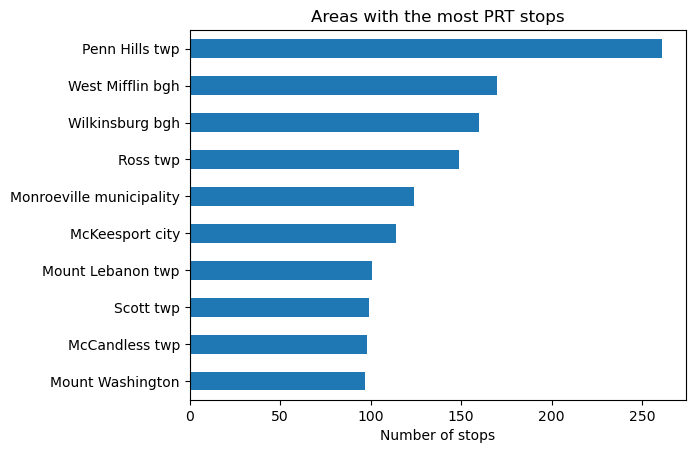

In [68]:
most_stops = stops["munihood_display"].value_counts().head(10)

most_stops.sort_values().plot.barh(title="Areas with the most PRT stops", xlabel="Number of stops", ylabel="")
most_stops

## Areas served by the most routes

munihood_display
Central Business District    79
South Shore                  31
Shadyside                    26
Larimer                      23
South Oakland                21
Wilkinsburg bgh              21
North Oakland                20
Bluff                        20
Point Breeze North           19
Central Oakland              19
Name: route, dtype: int64

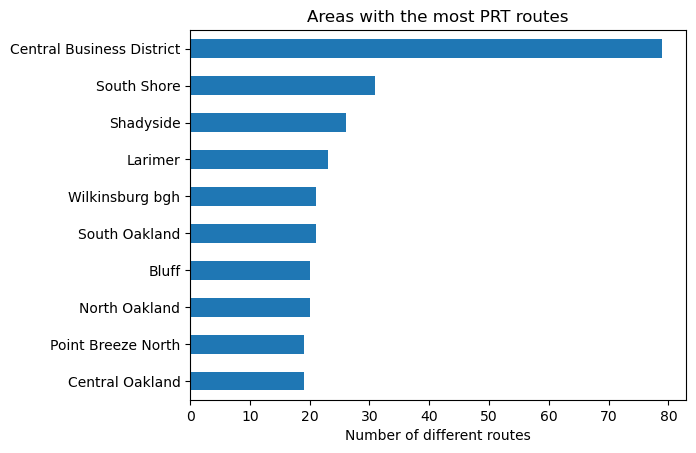

In [69]:
routes = stops[["munihood_display", "routes_served"]].copy()
routes["route"] = routes["routes_served"].str.split(",")
routes = routes.explode("route")

most_routes = routes.groupby("munihood_display")["route"].nunique().sort_values(ascending=False).head(10)

most_routes.sort_values().plot.barh(title="Areas with the most PRT routes", xlabel="Number of different routes", ylabel="")
most_routes